In [1]:
# STEP 1: EXPLORE THE FLEET

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Load the machine vibration dataset

df = pd.read_csv(
    "machine_vibration.csv",
    parse_dates=["date"]
)

df.head()

,date,machine_id,machine_name,vibration
0,2025-01-01,M-01,Press Alpha,2.746
1,2025-01-02,M-01,Press Alpha,2.527
2,2025-01-03,M-01,Press Alpha,2.346
3,2025-01-04,M-01,Press Alpha,2.233
4,2025-01-05,M-01,Press Alpha,2.324


In [3]:
# Dataset overview

print("Dataset shape:", df.shape)
print("Number of machines:", df["machine_id"].nunique())
print("Machine IDs:", df["machine_id"].unique())

print("\nDate range:")
print("Start date:", df["date"].min())
print("End date:", df["date"].max())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate machine-date records:")
print(df.duplicated(subset=["machine_id", "date"]).sum())

print("\nRecords per machine:")
print(df.groupby("machine_id").size())

Dataset shape: (2920, 4)
Number of machines: 8
Machine IDs: <StringArray>
['M-01', 'M-02', 'M-03', 'M-04', 'M-05', 'M-06', 'M-07', 'M-08']
Length: 8, dtype: str

Date range:
Start date: 2025-01-01 00:00:00
End date: 2025-12-31 00:00:00

Missing values:
date            0
machine_id      0
machine_name    0
vibration       0
dtype: int64

Duplicate machine-date records:
0

Records per machine:
machine_id
M-01    365
M-02    365
M-03    365
M-04    365
M-05    365
M-06    365
M-07    365
M-08    365
dtype: int64


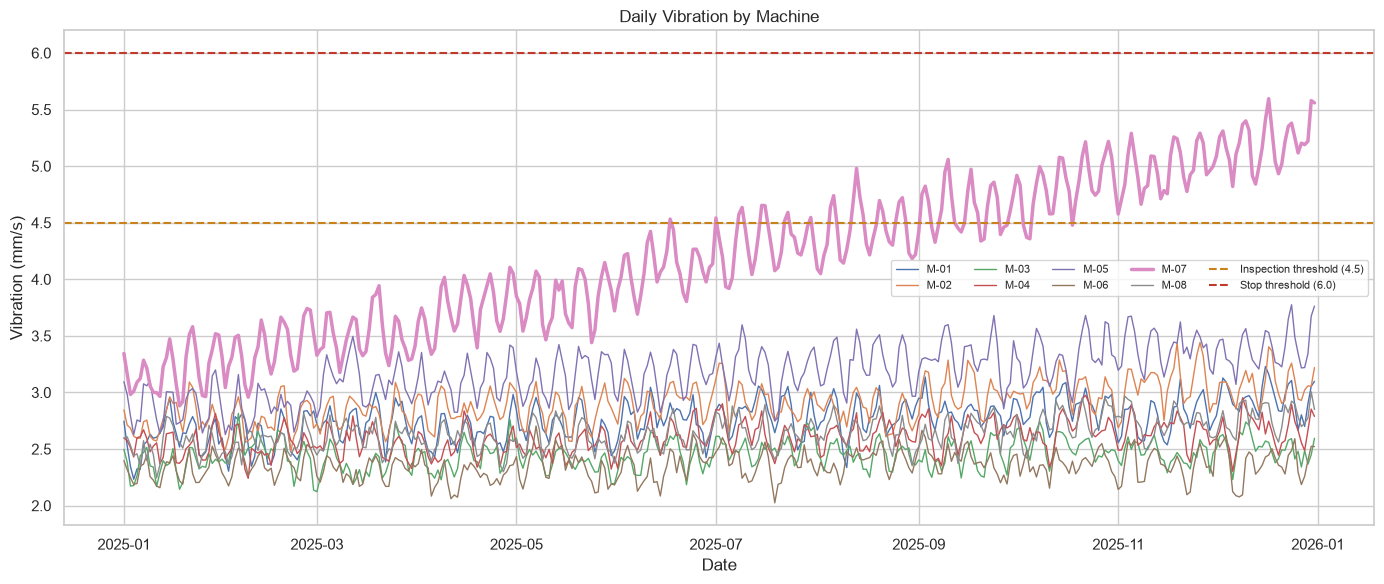

In [4]:
# Plot daily vibration for all machines

plt.figure(figsize=(14, 6))

for mid, g in df.groupby("machine_id"):
    g = g.sort_values("date")

    plt.plot(
        g.date,
        g.vibration,
        linewidth=2.5 if mid == "M-07" else 1.0,
        label=mid
    )

# Maintenance thresholds
plt.axhline(
    4.5, color="#C9821B",
    linestyle="--",
    label="Inspection threshold (4.5)"
)

plt.axhline(
    6.0, color="#C0392B",
    linestyle="--",
    label="Stop threshold (6.0)"
)

plt.title("Daily Vibration by Machine")
plt.xlabel("Date")
plt.ylabel("Vibration (mm/s)")
plt.legend(ncol=5, fontsize=8)
plt.tight_layout()
plt.show()

In [5]:
# STEP 2: SPLIT BY TIME, NOT AT RANDOM

# Extract the degrading machine
series = (
    df[df.machine_id == "M-07"]
    .sort_values("date")
    .set_index("date")["vibration"]
)

# Forecast horizon
H = 65

# Chronological train/test split
train, test = series.iloc[:-H], series.iloc[-H:]

print(
    train.index.min().date(), "to",
    train.index.max().date(), "->",
    test.index.min().date(), "to",
    test.index.max().date()
)

2025-01-01 to 2025-10-27 -> 2025-10-28 to 2025-12-31


In [6]:
# Validate the chronological split

print("Total observations:", len(series))
print("Training observations:", len(train))
print("Testing observations:", len(test))

print("\nTraining period:")
print(train.index.min(), "to", train.index.max())

print("\nTesting period:")
print(test.index.min(), "to", test.index.max())

assert train.index.max() < test.index.min()

print("\nTime-based split validated successfully!")

Total observations: 365
Training observations: 300
Testing observations: 65

Training period:
2025-01-01 00:00:00 to 2025-10-27 00:00:00

Testing period:
2025-10-28 00:00:00 to 2025-12-31 00:00:00

Time-based split validated successfully!


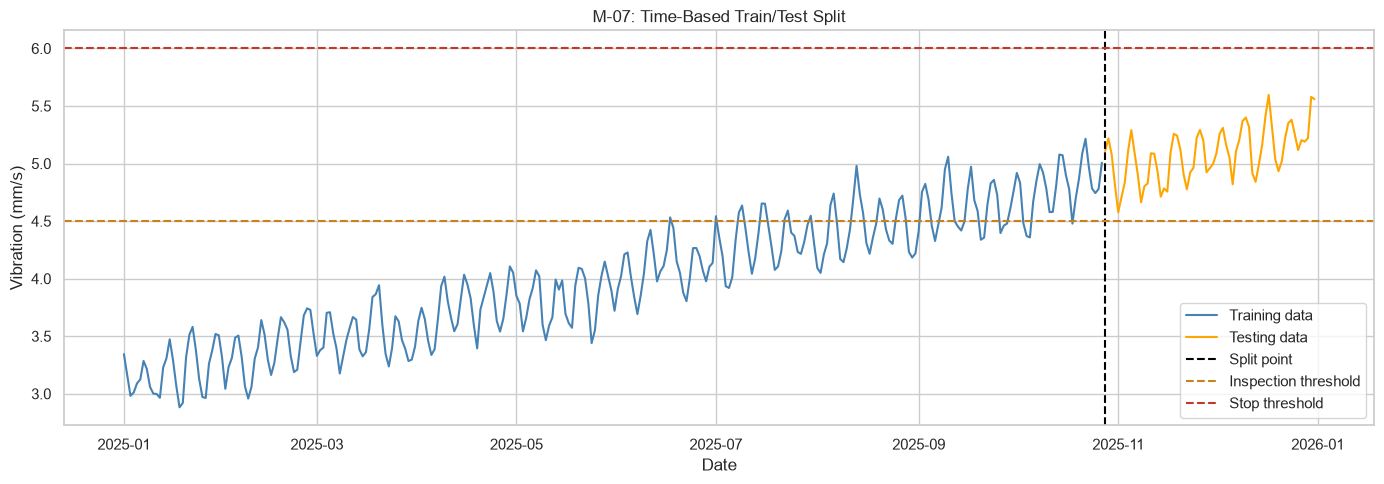

In [7]:
# Visualize the chronological split

plt.figure(figsize=(14, 5))

plt.plot(
    train.index, train.values,
    label="Training data",
    color="steelblue"
)

plt.plot(
    test.index, test.values,
    label="Testing data",
    color="orange"
)

plt.axvline(
    test.index.min(),
    color="black",
    linestyle="--",
    label="Split point"
)

plt.axhline(
    4.5, color="#C9821B",
    linestyle="--",
    label="Inspection threshold"
)

plt.axhline(
    6.0, color="#C0392B",
    linestyle="--",
    label="Stop threshold"
)

plt.title("M-07: Time-Based Train/Test Split")
plt.xlabel("Date")
plt.ylabel("Vibration (mm/s)")
plt.legend()
plt.tight_layout()
plt.show()

In [8]:
# STEP 3: THREE FORECASTING MODELS

# MODEL 1: Seasonal Naive

last_week = train.iloc[-7:].values

snaive = np.array([
    last_week[i % 7] for i in range(H)
])

print("Seasonal Naive forecast completed!")
print("Forecast length:", len(snaive))
print("First 7 predictions:", snaive[:7])

Seasonal Naive forecast completed!
Forecast length: 65
First 7 predictions: [5.087 5.215 4.973 4.783 4.743 4.779 5.007]


In [9]:
# MODEL 2: Holt-Winters

hw = ExponentialSmoothing(
    train,
    trend="add",
    seasonal="add",
    seasonal_periods=7
).fit()

hw_fc = hw.forecast(H).values

print("Holt-Winters forecast completed!")
print("Forecast length:", len(hw_fc))
print("First 7 predictions:", hw_fc[:7])

c:\Users\Hasandi Maheli\OneDrive\Desktop\Virtusa_assesments\Week7_TimeSeries\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


Holt-Winters forecast completed!
Forecast length: 65
First 7 predictions: [5.21156971 5.27203796 5.12403786 4.92041035 4.78822468 4.85266663
 5.03741078]


In [10]:
# MODEL 3: Gradient Boosting

# Feature engineering

def make_feats(s):

    d = pd.DataFrame({"y": s})

    d["lag1"] = d.y.shift(1)
    d["lag7"] = d.y.shift(7)
    d["dow"] = d.index.dayofweek

    return d.dropna()


# Create training features
tr = make_feats(train)

print("Feature dataset shape:", tr.shape)

tr.head()

Feature dataset shape: (293, 4)


,y,lag1,lag7,dow
date,,,,
2025-01-08,3.215,3.285,3.344,2
2025-01-09,3.058,3.215,3.165,3
2025-01-10,3.001,3.058,2.982,4
2025-01-11,2.998,3.001,3.011,5
2025-01-12,2.965,2.998,3.090,6


In [11]:
# Train Gradient Boosting

gb = GradientBoostingRegressor(
    n_estimators=200,
    max_depth=3,
    random_state=8
)

gb.fit(
    tr[["lag1", "lag7", "dow"]],
    tr["y"]
)

print("Gradient Boosting model trained successfully!")

Gradient Boosting model trained successfully!


In [12]:
# Recursive multi-step forecasting

hist = list(train.values)

gb_fc = []

for i in range(H):

    # Create input features
    x = [[
        hist[-1],
        hist[-7],
        test.index[i].dayofweek
    ]]

    # Predict next day's vibration
    p = gb.predict(x)[0]

    # Store prediction
    gb_fc.append(p)

    # Append prediction to history
    hist.append(p)

gb_fc = np.array(gb_fc)

print("Gradient Boosting forecast completed!")
print("Forecast length:", len(gb_fc))
print("First 7 predictions:", gb_fc[:7])

Gradient Boosting forecast completed!
Forecast length: 65
First 7 predictions: [5.15783732 5.19518195 4.95247897 4.82908407 4.78598334 4.91101558
 5.08440494]


In [13]:
# Validate forecasting outputs

forecasts = pd.DataFrame({
    "Seasonal Naive": snaive,
    "Holt-Winters": hw_fc,
    "Gradient Boosting": gb_fc
}, index=test.index)

assert len(snaive) == H
assert len(hw_fc) == H
assert len(gb_fc) == H
assert np.isfinite(forecasts.to_numpy()).all()

print("All three forecasts generated successfully!")
print("Forecast shape:", forecasts.shape)

forecasts.head(10)

All three forecasts generated successfully!
Forecast shape: (65, 3)


,Seasonal Naive,Holt-Winters,Gradient Boosting
date,,,
2025-10-28,5.087,5.211570,5.157837
2025-10-29,5.215,5.272038,5.195182
2025-10-30,4.973,5.124038,4.952479
2025-10-31,4.783,4.920410,4.829084
2025-11-01,4.743,4.788225,4.785983
2025-11-02,4.779,4.852667,4.911016
2025-11-03,5.007,5.037411,5.084405
2025-11-04,5.087,5.256470,5.223702
2025-11-05,5.215,5.316938,5.195182


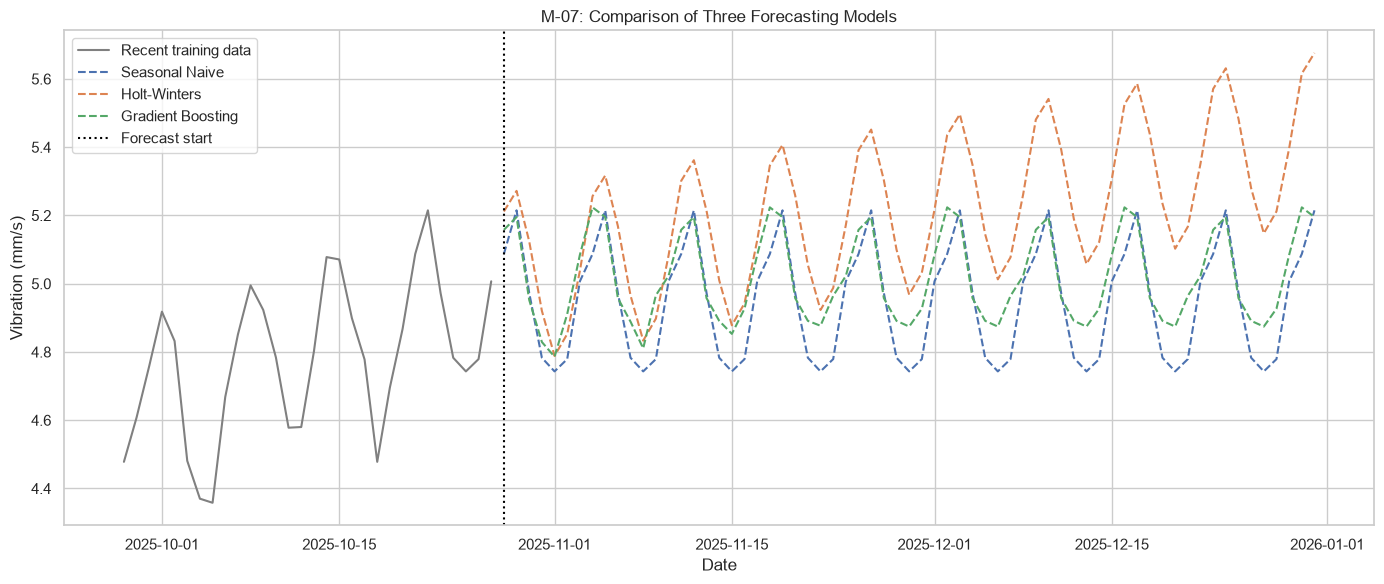

In [14]:
# Visualize the three forecasts

plt.figure(figsize=(14, 6))

plt.plot(
    train.index[-30:],
    train.values[-30:],
    color="gray",
    label="Recent training data"
)

plt.plot(
    test.index, snaive,
    linestyle="--",
    label="Seasonal Naive"
)

plt.plot(
    test.index, hw_fc,
    linestyle="--",
    label="Holt-Winters"
)

plt.plot(
    test.index, gb_fc,
    linestyle="--",
    label="Gradient Boosting"
)

plt.axvline(
    test.index.min(),
    color="black",
    linestyle=":",
    label="Forecast start"
)

plt.title("M-07: Comparison of Three Forecasting Models")
plt.xlabel("Date")
plt.ylabel("Vibration (mm/s)")
plt.legend()
plt.tight_layout()
plt.show()

In [15]:
# STEP 4: BACKTEST ON THE HELD-OUT FUTURE

# Function to calculate evaluation metrics

def sc(name, yhat):

    return {
        "model": name,
        "MAE": mean_absolute_error(test, yhat),
        "RMSE": mean_squared_error(test, yhat) ** 0.5,
        "MAPE%": float(
            np.mean(
                np.abs((test.values - yhat) / test.values)
            ) * 100
        )
    }


# Compare all three models

results = pd.DataFrame([
    sc("Seasonal naive", snaive),
    sc("Holt-Winters", hw_fc),
    sc("Gradient boosting", gb_fc)
]).set_index("model")

results.round(3)

,MAE,RMSE,MAPE%
model,,,
Seasonal naive,0.169,0.205,3.278
Holt-Winters,0.139,0.156,2.753
Gradient boosting,0.139,0.172,2.703


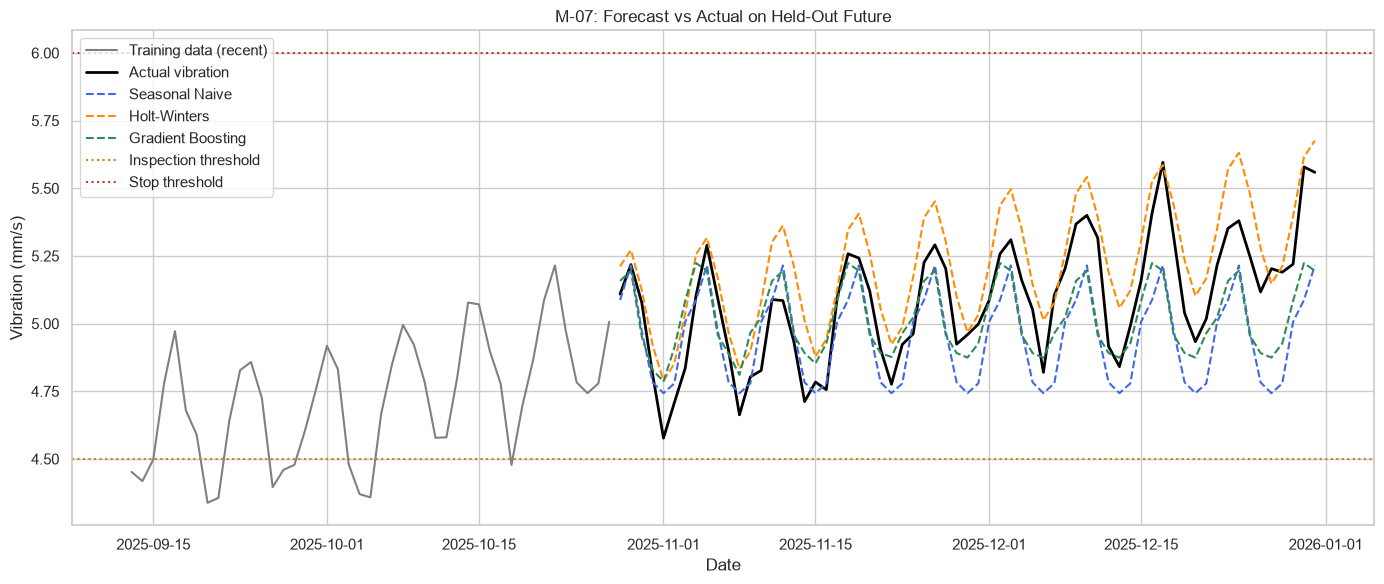

In [16]:
# Visualize backtesting results

plt.figure(figsize=(14, 6))

# Recent historical observations
plt.plot(
    train.index[-45:],
    train.values[-45:],
    color="gray",
    label="Training data (recent)"
)

# Actual test observations
plt.plot(
    test.index,
    test.values,
    color="black",
    linewidth=2,
    label="Actual vibration"
)

# Seasonal Naive
plt.plot(
    test.index,
    snaive,
    linestyle="--",
    color="royalblue",
    label="Seasonal Naive"
)

# Holt-Winters
plt.plot(
    test.index,
    hw_fc,
    linestyle="--",
    color="darkorange",
    label="Holt-Winters"
)

# Gradient Boosting
plt.plot(
    test.index,
    gb_fc,
    linestyle="--",
    color="seagreen",
    label="Gradient Boosting"
)

# Maintenance thresholds
plt.axhline(
    4.5, color="#C9821B",
    linestyle=":",
    label="Inspection threshold"
)

plt.axhline(
    6.0, color="#C0392B",
    linestyle=":",
    label="Stop threshold"
)

plt.title("M-07: Forecast vs Actual on Held-Out Future")
plt.xlabel("Date")
plt.ylabel("Vibration (mm/s)")
plt.legend()
plt.tight_layout()
plt.show()

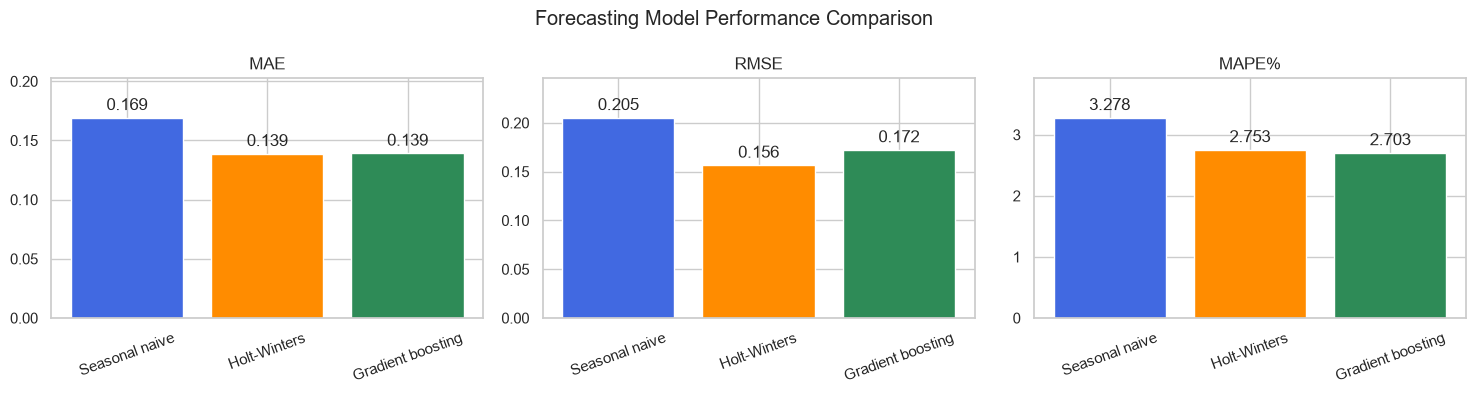

In [17]:
# Compare forecasting errors

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

metrics = ["MAE", "RMSE", "MAPE%"]

colors = ["royalblue", "darkorange", "seagreen"]

for ax, metric in zip(axes, metrics):

    bars = ax.bar(
        results.index,
        results[metric],
        color=colors
    )

    ax.set_title(metric)
    ax.tick_params(axis="x", rotation=20)
    ax.bar_label(bars, fmt="%.3f", padding=3)
    ax.set_ylim(0, results[metric].max() * 1.2)

plt.suptitle("Forecasting Model Performance Comparison")
plt.tight_layout()
plt.show()

In [18]:
# Identify the best model for each metric

for metric in ["MAE", "RMSE", "MAPE%"]:

    best_model = results[metric].idxmin()
    best_score = results[metric].min()

    print(
        f"Best model by {metric}: "
        f"{best_model} ({best_score:.3f})"
    )

Best model by MAE: Holt-Winters (0.139)
Best model by RMSE: Holt-Winters (0.156)
Best model by MAPE%: Gradient boosting (2.703)


In [26]:
# STEP 4: BACKTEST ON THE HELD-OUT FUTURE

# Define a function to calculate forecasting evaluation metrics
def sc(name, yhat):

    return {
        "model": name,

        # Calculate Mean Absolute Error
        "MAE": mean_absolute_error(test, yhat),

        # Calculate Root Mean Squared Error
        "RMSE": mean_squared_error(test, yhat) ** 0.5,

        # Calculate Mean Absolute Percentage Error
        "MAPE%": float(np.mean(np.abs(
            (test.values - yhat) / test.values
        )) * 100)
    }


# Evaluate and compare the three forecasting models
pd.DataFrame([
    sc("Seasonal naive", snaive),
    sc("Holt-Winters", hw_fc),
    sc("Gradient boosting", gb_fc)
]).set_index("model").round(3)

,MAE,RMSE,MAPE%
model,,,
Seasonal naive,0.169,0.205,3.278
Holt-Winters,0.139,0.156,2.753
Gradient boosting,0.139,0.172,2.703


In [27]:
# STEP 5: THE EXTRAPOLATION TRAP

# Define the future forecasting horizon as 120 days
FUT = 120


# 1. HOLT-WINTERS FORECASTING

# Train Holt-Winters using the entire historical series
# Include additive trend and weekly seasonality
hw_full = ExponentialSmoothing(
    series,
    trend="add",
    seasonal="add",
    seasonal_periods=7
).fit()

# Generate dates for the next 120 days
idx = pd.date_range(
    series.index[-1] + pd.Timedelta(days=1),
    periods=FUT
)

# Generate the Holt-Winters future forecast
hw_future = pd.Series(
    hw_full.forecast(FUT).values,
    index=idx
)


# 2. GRADIENT BOOSTING FORECASTING

# Create lag features using the entire historical series
full = make_feats(series)

# Initialize the Gradient Boosting model
gb_full = GradientBoostingRegressor(
    n_estimators=200,
    max_depth=3,
    random_state=8
)

# Train the model using lag1, lag7 and day-of-week features
gb_full.fit(
    full[["lag1", "lag7", "dow"]],
    full["y"]
)

# Initialize historical observations and prediction list
hist = list(series.values)
gb_future = []

# Perform recursive forecasting for the next 120 days
for i in range(FUT):

    # Prepare input features for the next prediction
    x = [[hist[-1], hist[-7], idx[i].dayofweek]]

    # Predict the next day's vibration
    p = gb_full.predict(x)[0]

    # Store the predicted vibration value
    gb_future.append(p)

    # Append the prediction to history for future predictions
    hist.append(p)

# Convert Gradient Boosting predictions into a time series
gb_future = pd.Series(gb_future, index=idx)


# 3. COMPARE MAXIMUM FORECASTED VIBRATION

# Display the maximum vibration predicted by Holt-Winters
print("Holt-Winters max:", round(hw_future.max(), 2))

# Display the maximum vibration predicted by Gradient Boosting
print("Gradient boosting max:", round(gb_future.max(), 2),
      "(never reaches 6.0)")

c:\Users\Hasandi Maheli\OneDrive\Desktop\Virtusa_assesments\Week7_TimeSeries\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


Holt-Winters max: 6.31
Gradient boosting max: 5.53 (never reaches 6.0)


In [28]:
# STEP 6: PREDICTIVE MAINTENANCE ACROSS THE FLEET

# Define a function to calculate days until a threshold is reached
def days_to_threshold(s, level, horizon=180):

    # Fit Holt-Winters with additive trend and weekly seasonality
    fit = ExponentialSmoothing(
        s,
        trend="add",
        seasonal="add",
        seasonal_periods=7
    ).fit()

    # Generate future dates for the forecasting horizon
    idx = pd.date_range(
        s.index[-1] + pd.Timedelta(days=1),
        periods=horizon
    )

    # Forecast future vibration levels
    fc = pd.Series(fit.forecast(horizon).values, index=idx)

    # Identify forecasts that reach or exceed the threshold
    hit = fc[fc >= level]

    # Return days until the first predicted threshold crossing
    return None if hit.empty else (hit.index[0] - s.index[-1]).days


# Initialize a list to store fleet maintenance results
rows = []

# Process each machine individually
for mid, g in df.groupby("machine_id"):

    # Extract and sort the machine's vibration time series
    s = g.sort_values("date").set_index("date")["vibration"]

    # Obtain the latest vibration reading
    latest = s.iloc[-1]

    # Calculate days until the inspection threshold is reached
    d_inspect = 0 if latest >= 4.5 else days_to_threshold(s, 4.5)

    # Classify the machine based on its maintenance priority
    status = (
        "URGENT" if latest >= 4.5 or
        (d_inspect is not None and d_inspect <= 30)
        else "watch" if d_inspect is not None
        else "healthy"
    )

    # Store the maintenance results for each machine
    rows.append({
        "machine": mid,
        "latest": round(latest, 2),
        "days_to_inspect": d_inspect,
        "days_to_stop": days_to_threshold(s, 6.0),
        "status": status
    })


# Display the fleet triage table sorted by latest vibration
pd.DataFrame(rows).sort_values(
    "latest", ascending=False
).set_index("machine")

c:\Users\Hasandi Maheli\OneDrive\Desktop\Virtusa_assesments\Week7_TimeSeries\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
c:\Users\Hasandi Maheli\OneDrive\Desktop\Virtusa_assesments\Week7_TimeSeries\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
c:\Users\Hasandi Maheli\OneDrive\Desktop\Virtusa_assesments\Week7_TimeSeries\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
c:\Users\Hasandi Maheli\OneDrive\Desktop\Virtusa_assesments\Week7_TimeSeries\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred freque

,latest,days_to_inspect,days_to_stop,status
machine,,,,
M-07,5.56,0.0,70.0,URGENT
M-05,3.76,NaN,NaN,healthy
M-02,3.22,NaN,NaN,healthy
M-01,3.10,NaN,NaN,healthy
M-08,2.85,NaN,NaN,healthy
M-04,2.79,NaN,NaN,healthy
M-03,2.60,NaN,NaN,healthy
M-06,2.52,NaN,NaN,healthy


In [ ]:
# ## STEP 7: WHEN TO RETRAIN

# A forecasting model becomes less reliable as new data
# arrives and machine conditions change.

# ### 1. Scheduled Retraining
# Refit the model weekly using all available data to date.
# This is computationally inexpensive and predictable
# for a slow daily vibration signal.

# ### 2. Triggered Retraining
# Monitor the rolling forecast error over the last 7 days.
# When the error exceeds a predefined threshold, retrain
# the model because machine behaviour may have changed.

# ### 3. Post-Repair Retraining
# Retrain the model immediately after any machine repair.
# A repair resets the degradation curve, meaning the
# previous data no longer accurately describes the machine.